# 01 — Replikasi Baseline (Minggu 1)

**Acuan:** Luna-Jiménez et al. (2022), *A Proposal for Multimodal Emotion Recognition Using Aural Transformers and Action Units on RAVDESS Dataset*, Applied Sciences 12(1):327 — kode: repo `MMEmotionRecognition` (MIT).

**Yang direplikasi di notebook ini** (semuanya memakai protokol paper: *subject-wise 5-fold CV*, 1.440 video speech RAVDESS, 8 emosi, seed 2020):

| Blok | Isi | Tabel/gambar di paper | Perlu GPU / data mentah? |
|---|---|---|---|
| A | Model statis pada rata-rata Action Units (SVC, k-NN, MLP; ± normalisasi) | Tabel 2 | Tidak |
| B | Model statis pada rata-rata embedding xlsr-Wav2Vec2.0 512-d (SVC, k-NN, MLP) | Tabel 1 (baris *Feature Extraction*) | Tidak |
| C | Late fusion (LogReg) atas posterior FT-Wav2Vec2 + bi-LSTM + MLP80 | Tabel 3, Gambar 7–8, **86,70 %** | Tidak (memakai posterior rilisan penulis) |
| D | Fine-tuning Wav2Vec2 (81,82 %) & bi-LSTM AU (62,13 %) dari awal | Tabel 1/2, Gambar 5–6 | **Ya** — lihat bagian "Mode penuh" di bawah |

> Blok A–C memakai fitur/posterior yang **sudah dibundel penulis di dalam repo** (`data/trainingData`, `data/posteriors`), jadi bisa jalan di laptop biasa tanpa mengunduh RAVDESS.

## 1. Setup, seed, dan log lingkungan

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
import rav_utils as u

u.set_seed()
REPO_DIR = u.find_repo(r"D:\PSD\PSD-Projek\ravdess_project\ravdess_project\MMEmotionRecognition-main\MMEmotionRecognition-main")
          # folder hasil ekstrak MMEmotionRecognition-main.zip (harus di samping notebook ini)
os.makedirs("results", exist_ok=True)
env = u.env_log("results/env_log.json", {"repo": os.path.basename(REPO_DIR)})
env

{'python': '3.13.7',
 'platform': 'Windows-11-10.0.26300-SP0',
 'numpy': '2.5.4',
 'pandas': '3.1.0',
 'scikit-learn': '1.9.1',
 'scipy': '1.18.1',
 'seed': 2020,
 'folds': {0: [2, 5, 14, 15, 16],
  1: [3, 6, 7, 13, 18],
  2: [10, 11, 12, 19, 20],
  3: [8, 17, 21, 23, 24],
  4: [1, 4, 9, 22]},
 'repo': 'MMEmotionRecognition-main'}

## 2. Cek data & protokol evaluasi

In [2]:
au, au_feat = u.load_au_avg(REPO_DIR)
emb, emb_feat = u.load_audio_emb(REPO_DIR)
print("AU rata-rata :", au.shape, "-> fitur:", len(au_feat))
print("Emb audio    :", emb.shape, "-> fitur:", len(emb_feat))
print("Distribusi kelas (0=neutral,1=calm,...,7=surprised):", np.bincount(au.y).tolist(), "(neutral 96 karena hanya 1 intensitas)")

# Pastikan tidak ada aktor yang muncul di dua fold (subject-wise)
all_actors = sorted(a for v in u.FOLDS.values() for a in v)
assert all_actors == list(range(1, 25)), "aktor harus 1..24 masing-masing tepat satu fold"
pd.DataFrame({"fold": list(u.FOLDS), "aktor_validasi": [str(v) for v in u.FOLDS.values()],
              "n_video": [int(au.actor.isin(v).sum()) for v in u.FOLDS.values()]})

AU rata-rata : (1440, 41) -> fitur: 35
Emb audio    : (1440, 518) -> fitur: 512
Distribusi kelas (0=neutral,1=calm,...,7=surprised): [96, 192, 192, 192, 192, 192, 192, 192] (neutral 96 karena hanya 1 intensitas)


,fold,aktor_validasi,n_video
0,0,"[2, 5, 14, 15, 16]",300
1,1,"[3, 6, 7, 13, 18]",300
2,2,"[10, 11, 12, 19, 20]",300
3,3,"[8, 17, 21, 23, 24]",300
4,4,"[1, 4, 9, 22]",240


## 3. Blok A — Facial: model statis pada rata-rata Action Units (Tabel 2 paper)
Nilai paper dicatat apa adanya dari Tabel 2. `norm=True` berarti MinMax 0–1 (di repo: `--type_of_norm 1`).

In [3]:
# (model, hyperparameter, norm) -> akurasi paper (%)
PAPER_AU = {
 ("SVC","C=0.1",True):53.25, ("SVC","C=0.1",False):48.07, ("SVC","C=1.0",True):59.93, ("SVC","C=1.0",False):54.88,
 ("SVC","C=10.0",True):55.93, ("SVC","C=10.0",False):51.65,
 ("kNN","k=10",True):53.10, ("kNN","k=10",False):46.80, ("kNN","k=20",True):54.30, ("kNN","k=20",False):49.07,
 ("kNN","k=30",True):55.18, ("kNN","k=30",False):48.82, ("kNN","k=40",True):55.40, ("kNN","k=40",False):50.20,
 ("MLP","1 layer (80)",True):60.22, ("MLP","1 layer (80)",False):58.93,
 ("MLP","2 layers (80,80)",True):57.77, ("MLP","2 layers (80,80)",False):55.82,
}
def factory(model, hp):
    if model == "SVC": return lambda: SVC(C=float(hp.split("=")[1]), random_state=u.SEED)
    if model == "kNN": return lambda: KNeighborsClassifier(n_neighbors=int(hp.split("=")[1]))
    if model == "MLP": return lambda: MLPClassifier(hidden_layer_sizes=(80,) if hp.startswith("1") else (80, 80), random_state=u.SEED)

rows, long_rows = [], []
for (model, hp, norm), paper in PAPER_AU.items():
    r = u.run_cv(au, au_feat, factory(model, hp), norm="minmax" if norm else None)
    acc = np.mean(r["acc"])
    rows.append({"Model": model, "Hyper-param": hp, "Norm": "Ya" if norm else "Tidak", "Paper (%)": paper,
                 "Replikasi (%)": round(acc, 2), "Selisih": round(acc - paper, 2) + 0.0, "F1-macro (%)": round(np.mean(r["f1"]), 2),
                 "±95% CI": round(u.ci95(r["acc"]), 2)})
    for f in range(5):
        long_rows.append({"experiment": f"AUstatic_{model}_{hp}_norm{int(norm)}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]})
tabA = pd.DataFrame(rows)
u.append_results("results/results_long_m1.csv", long_rows)
tabA.to_csv("results/tabel_replikasi_AU.csv", index=False)
tabA

,Model,Hyper-param,Norm,Paper (%),Replikasi (%),Selisih,F1-macro (%),±95% CI
0,SVC,C=0.1,Ya,53.25,53.25,0.0,49.52,2.58
1,SVC,C=0.1,Tidak,48.07,48.07,0.0,41.79,2.58
2,SVC,C=1.0,Ya,59.93,59.93,0.0,59.51,2.53
3,SVC,C=1.0,Tidak,54.88,54.88,0.0,53.81,2.57
4,SVC,C=10.0,Ya,55.93,55.93,0.0,55.29,2.56
5,SVC,C=10.0,Tidak,51.65,51.65,0.0,51.71,2.58
6,kNN,k=10,Ya,53.10,53.10,0.0,52.43,2.58
7,kNN,k=10,Tidak,46.80,46.80,0.0,45.79,2.58
8,kNN,k=20,Ya,54.30,54.30,0.0,52.83,2.57
9,kNN,k=20,Tidak,49.07,49.07,0.0,47.18,2.58


In [4]:
print(f"Selisih absolut rata-rata vs paper : {tabA['Selisih'].abs().mean():.2f} poin")
print(f"Selisih absolut terbesar           : {tabA['Selisih'].abs().max():.2f} poin")

Selisih absolut rata-rata vs paper : 0.00 poin
Selisih absolut terbesar           : 0.00 poin


## 4. Blok B — Audio: model statis pada rata-rata embedding feature-encoder (Tabel 1 paper)
Di Tabel 1 paper tidak ada kolom normalisasi; contoh perintah di README repo memakai `--type_of_norm 2` (tanpa normalisasi), jadi di sini juga tanpa normalisasi.

In [5]:
PAPER_AUD = {("SVC","C=1.0"):50.13, ("SVC","C=10.0"):53.12, ("SVC","C=100.0"):53.10,
             ("kNN","k=10"):36.07, ("kNN","k=20"):37.90, ("kNN","k=30"):38.65, ("kNN","k=40"):38.47,
             ("MLP","1 layer (80)"):56.53, ("MLP","2 layers (80,80)"):55.82}
rows, long_rows = [], []
for (model, hp), paper in PAPER_AUD.items():
    r = u.run_cv(emb, emb_feat, factory(model, hp), norm=None)
    acc = np.mean(r["acc"])
    rows.append({"Model": model, "Hyper-param": hp, "Paper (%)": paper, "Replikasi (%)": round(acc, 2),
                 "Selisih": round(acc - paper, 2) + 0.0, "F1-macro (%)": round(np.mean(r["f1"]), 2), "±95% CI": round(u.ci95(r["acc"]), 2)})
    for f in range(5):
        long_rows.append({"experiment": f"AudioFE_{model}_{hp}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]})
tabB = pd.DataFrame(rows)
u.append_results("results/results_long_m1.csv", long_rows)
tabB.to_csv("results/tabel_replikasi_audioFE.csv", index=False)
tabB

,Model,Hyper-param,Paper (%),Replikasi (%),Selisih,F1-macro (%),±95% CI
0,SVC,C=1.0,50.13,50.13,0.0,47.61,2.58
1,SVC,C=10.0,53.12,53.12,0.0,52.29,2.58
2,SVC,C=100.0,53.10,53.10,0.0,52.27,2.58
3,kNN,k=10,36.07,36.07,0.0,34.89,2.48
4,kNN,k=20,37.90,37.90,0.0,36.04,2.51
5,kNN,k=30,38.65,38.65,0.0,36.59,2.52
6,kNN,k=40,38.47,38.47,0.0,36.09,2.51
7,MLP,1 layer (80),56.53,56.53,0.0,55.93,2.56
8,MLP,"2 layers (80,80)",55.82,55.82,0.0,54.97,2.56


## 5. Blok C — Late fusion (hasil utama paper: 86,70 %)
Pipeline sesuai `src/Fusion/FusionTraining.py`: posterior 8-d dari tiga model (FT-Wav2Vec2, bi-LSTM+attention, MLP80 pada rata-rata AU) digabung (24-d) → MinMax 0–1 → Logistic Regression (C=1).

>posterior ketiga model berasal dari **checkpoint rilisan penulis** (`data/posteriors`), bukan hasil training ulang kita. Jadi blok ini memverifikasi *tahap fusi + evaluasi*, bukan fine-tuning-nya.

In [6]:
fus = u.fusion_cv(REPO_DIR)
print("Akurasi per fold :", [round(a, 2) for a in fus["acc"]])
print(f"Akurasi rata-rata: {np.mean(fus['acc']):.2f} %   (paper: 86.70 %)   ±95% CI: {u.ci95(fus['acc']):.2f}")
print(f"F1-macro rata-rata: {np.mean(fus['f1']):.2f} %")
u.append_results("results/results_long_m1.csv",
    [{"experiment": "Fusion_baseline_LR", "fold": f, "acc": fus["acc"][f], "f1_macro": fus["f1"][f]} for f in range(5)])

Akurasi per fold : [88.67, 88.67, 84.67, 85.67, 85.83]
Akurasi rata-rata: 86.70 %   (paper: 86.70 %)   ±95% CI: 1.75
F1-macro rata-rata: 86.58 %


,experiment,fold,acc,f1_macro
0,AUstatic_SVC_C=0.1_norm1,0,54.666667,50.325221
1,AUstatic_SVC_C=0.1_norm1,1,52.666667,46.239162
2,AUstatic_SVC_C=0.1_norm1,2,55.333333,51.102433
3,AUstatic_SVC_C=0.1_norm1,3,49.000000,46.733560
4,AUstatic_SVC_C=0.1_norm1,4,54.583333,53.220888
...,...,...,...,...
135,Fusion_baseline_LR,0,88.666667,89.085185
136,Fusion_baseline_LR,1,88.666667,87.919677
137,Fusion_baseline_LR,2,84.666667,84.497695
138,Fusion_baseline_LR,3,85.666667,85.170885


In [7]:
# Tabel 3 paper: precision & recall per emosi (rata-rata 5-CV)
PAPER_P = [88.31, 91.45, 89.79, 71.22, 91.78, 88.26, 93.99, 89.50]
PAPER_R = [82.25, 85.63, 89.25, 81.88, 92.37, 83.62, 88.50, 87.87]
names = ["Neutral","Calm","Happy","Sad","Angry","Fearful","Disgusted","Surprised"]
P, R = u.per_class_pr(fus["yt_list"], fus["yp_list"])
tabC = pd.DataFrame({"Emosi": names, "Prec paper": PAPER_P, "Prec replikasi": P.round(2), "Rec paper": PAPER_R, "Rec replikasi": R.round(2)})
tabC["Δ Prec"] = (tabC["Prec replikasi"] - tabC["Prec paper"]).round(2) + 0.0
tabC["Δ Rec"] = (tabC["Rec replikasi"] - tabC["Rec paper"]).round(2) + 0.0
tabC.to_csv("results/tabel_replikasi_per_emosi.csv", index=False)
tabC

,Emosi,Prec paper,Prec replikasi,Rec paper,Rec replikasi,Δ Prec,Δ Rec
0,Neutral,88.31,88.31,82.25,82.25,0.0,0.00
1,Calm,91.45,91.45,85.63,85.62,0.0,-0.01
2,Happy,89.79,89.79,89.25,89.25,0.0,0.00
3,Sad,71.22,71.22,81.88,81.88,0.0,0.00
4,Angry,91.78,91.78,92.37,92.38,0.0,0.01
5,Fearful,88.26,88.26,83.62,83.62,0.0,0.00
6,Disgusted,93.99,93.99,88.50,88.50,0.0,0.00
7,Surprised,89.50,89.50,87.87,87.87,0.0,0.00


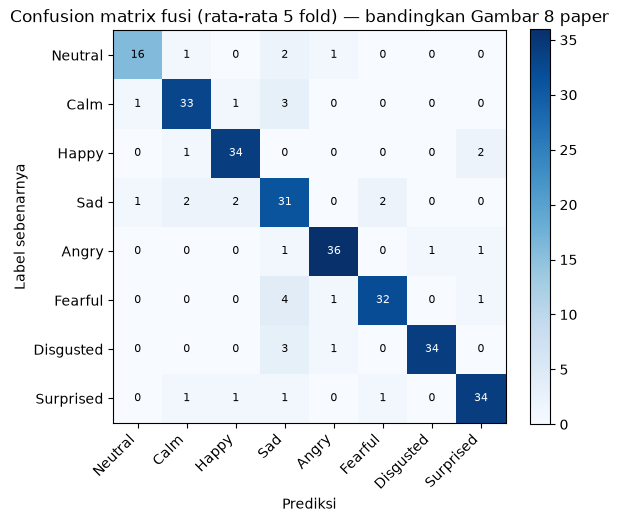

In [8]:
from sklearn.metrics import confusion_matrix
cm = sum(confusion_matrix(t, p, labels=range(8)) for t, p in zip(fus["yt_list"], fus["yp_list"])) / 5
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm.round(), cmap="Blues")
ax.set_xticks(range(8)); ax.set_yticks(range(8)); ax.set_xticklabels(names, rotation=45, ha="right"); ax.set_yticklabels(names)
for i in range(8):
    for j in range(8):
        ax.text(j, i, int(round(cm[i, j])), ha="center", va="center", color="white" if cm[i, j] > 20 else "black", fontsize=8)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya"); ax.set_title("Confusion matrix fusi (rata-rata 5 fold) — bandingkan Gambar 8 paper")
plt.colorbar(im); plt.tight_layout(); plt.savefig("results/cm_fusion_replikasi.png", dpi=150); plt.show()

## 6. Tabel ringkasan replikasi vs paper

In [9]:
summary = pd.DataFrame([
 ["Fusi: FT-Wav2Vec2 + bi-LSTM + MLP80 (LogReg)", 86.70, round(np.mean(fus["acc"]), 2), "Replikasi dari posterior rilisan penulis"],
 ["Visual: MLP(80) rata-rata AU, norm", 60.22, float(tabA.query("Model=='MLP' and `Hyper-param`=='1 layer (80)' and Norm=='Ya'")["Replikasi (%)"].iloc[0]), "Retrain dari fitur AU rilisan"],
 ["Visual: SVC C=1, norm", 59.93, float(tabA.query("Model=='SVC' and `Hyper-param`=='C=1.0' and Norm=='Ya'")["Replikasi (%)"].iloc[0]), "Retrain dari fitur AU rilisan"],
 ["Audio FE: MLP(80) emb 512-d", 56.53, float(tabB.query("Model=='MLP' and `Hyper-param`=='1 layer (80)'")["Replikasi (%)"].iloc[0]), "Retrain dari emb rilisan"],
 ["Audio FE: SVC C=10 emb 512-d", 53.12, float(tabB.query("Model=='SVC' and `Hyper-param`=='C=10.0'")["Replikasi (%)"].iloc[0]), "Retrain dari emb rilisan"],
 ["Audio FT-Wav2Vec2 + MLP(1024,8)", 81.82, None, "Belum direplikasi (butuh GPU + audio RAVDESS) — lihat Mode penuh"],
 ["Visual bi-LSTM + attention (AU per frame)", 62.13, None, "Belum direplikasi (butuh OpenFace + training) — lihat Mode penuh"],
], columns=["Sistem", "Paper (%)", "Replikasi (%)", "Status"])
summary["Selisih"] = (summary["Replikasi (%)"] - summary["Paper (%)"]).round(2) + 0.0
summary.to_csv("results/tabel_ringkasan_M1.csv", index=False)
summary

,Sistem,Paper (%),Replikasi (%),Status,Selisih
0,Fusi: FT-Wav2Vec2 + bi-LSTM + MLP80 (LogReg),86.70,86.70,Replikasi dari posterior rilisan penulis,0.0
1,"Visual: MLP(80) rata-rata AU, norm",60.22,60.22,Retrain dari fitur AU rilisan,0.0
2,"Visual: SVC C=1, norm",59.93,59.93,Retrain dari fitur AU rilisan,0.0
3,Audio FE: MLP(80) emb 512-d,56.53,56.53,Retrain dari emb rilisan,0.0
4,Audio FE: SVC C=10 emb 512-d,53.12,53.12,Retrain dari emb rilisan,0.0
5,"Audio FT-Wav2Vec2 + MLP(1024,8)",81.82,NaN,Belum direplikasi (butuh GPU + audio RAVDESS) ...,NaN
6,Visual bi-LSTM + attention (AU per frame),62.13,NaN,Belum direplikasi (butuh OpenFace + training) ...,NaN


## 7. Mode penuh (opsional): fine-tuning & bi-LSTM dari data mentah
Bagian ini **tidak dijalankan di notebook ini** karena butuh GPU (disarankan ≥16 GB VRAM; Google Colab/Kaggle cukup) dan data mentah. Urutan menurut README repo:

1. Unduh RAVDESS dari Zenodo (record 1188976): `Video_Speech_Actor_01..24.zip` (~5,8 GB). Ambil hanya 1.440 file di `data/ravdess_videos.csv`.
2. `python src/Audio/preProcessing/process_audio.py --videos_dir <RAVDESS>/videos --out_dir <RAVDESS>/audios_16kHz` (perlu `ffmpeg`).
3. Fine-tuning: `python src/Audio/FineTuningWav2Vec/main_FineTuneWav2Vec_CV.py --audios_dir ... --model_id jonatasgrosman/wav2vec2-large-xlsr-53-english` (batch 100, 10 epoch, lr 1e-3, 5 fold).
4. AU: ekstraksi OpenFace 2.0 (`src/Video/OpenFace/AUsFeatureExtractor.py`), lalu bi-LSTM via `src/Video/models/sequenceLearning/` (lihat `README_AUS.md`).

**kompatibilitas:** `requirements.txt` asli repo mengunci versi 2021–2022 (torch 1.10, numpy 1.22, pandas 1.3.5, numba 0.54) yang tidak bisa dipasang di Python ≥ 3.10; dan skrip `FeatureTrainingAUs.py` / `FeatureTraining.py` memakai `DataFrame.append` & `np.float` yang sudah dihapus di pandas 2 / numpy ≥ 1.24. Karena itu blok A–C di atas mengimplementasikan ulang logika yang sama dengan panggilan scikit-learn yang identik, bukan memanggil skrip repo apa adanya.

## 8. Catatan deviasi (untuk laporan)

| # | Deviasi | Dampak |
|---|---|---|
| 1 | Fitur AU rata-rata & embedding audio 512-d **tidak diekstrak ulang**; dipakai file rilisan penulis di `data/trainingData`. | Preprocessing (OpenFace, ffmpeg) tidak ikut divalidasi. |
| 2 | Posterior FT-Wav2Vec2, bi-LSTM, dan MLP80 untuk fusi diambil dari `data/posteriors` (checkpoint penulis), bukan training ulang. | Angka 86,70 % memverifikasi tahap fusi saja. Akurasi unimodal 81,82 % / 62,13 % belum direplikasi. |
| 3 | Versi pustaka berbeda: paper/repo scikit-learn 1.0.2, pandas 1.3.5, numpy 1.22; di sini versi terbaru (lihat `results/env_log.json`). | Pada percobaan ini seluruh angka tetap identik dengan paper (selisih 0,00 poin), termasuk MLP dengan seed 2020. Jika Anda memakai versi scikit-learn lain dan MLP bergeser sedikit, catat di sini. |
| 4 | Hardware: CPU saja (tanpa GPU). | Tidak mempengaruhi blok A–C; membatasi blok D. |
| 5 | Perhitungan CI 95 % memakai pendekatan binomial `1,96·√(p(1−p)/N)` dengan N = 1440; paper tidak merinci rumusnya. | Nilai CI paper (mis. ±2,56) cocok dengan rumus ini. |
| 6 | Pada fusi, regresi logistik dilatih pada posterior **train** dari model yang sudah melihat data itu (in-sample), seperti di kode penulis. | Potensi *optimistic bias* — layak dibahas di bagian keterbatasan artikel (Minggu 4). |